In [1]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

import timm

print("Imports successful.")

Matplotlib is building the font cache; this may take a moment.


Imports successful.


In [6]:
# ============================================================
# CELL 2 — CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()

DATASET_DIR = PROJECT_ROOT / "archive"
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR = RESULTS_DIR / "models"
PLOT_DIR = RESULTS_DIR / "plots"
EMBEDDING_DIR = RESULTS_DIR / "embeddings"
GRADCAM_DIR = RESULTS_DIR / "gradcam"

for directory in [
    DATA_DIR,
    RESULTS_DIR,
    MODEL_DIR,
    PLOT_DIR,
    EMBEDDING_DIR,
    GRADCAM_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


CLASSES = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "normal-cecum",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

NUM_CLASSES = len(CLASSES)

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASSES)
}

INDEX_TO_CLASS = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}


IMAGE_SIZE = 224
BATCH_SIZE = 8
NUM_EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

RANDOM_SEED = 42

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("Classes:", NUM_CLASSES)

Project root: /Users/sudeep/Documents/Major Project/notebooks
Dataset: /Users/sudeep/Documents/Major Project/notebooks/archive
Classes: 6


In [3]:
# ============================================================
# CELL 3 — RANDOM SEED
# ============================================================

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


In [7]:
# ============================================================
# CELL 4 — DEVICE
# ============================================================

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", DEVICE)

PyTorch version: 2.14.1
MPS available: True
CUDA available: False
Selected device: mps


In [8]:
# ============================================================
# CELL 5 — DATASET DISCOVERY
# ============================================================

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

records = []

for class_name in CLASSES:

    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_files = [
        file
        for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    print(
        f"{class_name:30s}: {len(image_files)}"
    )

    for image_path in image_files:

        records.append({
            "image_path": str(image_path),
            "class_name": class_name,
            "label": CLASS_TO_INDEX[class_name]
        })


df = pd.DataFrame(records)

print("\nTotal images:", len(df))

dyed-lifted-polyps            : 1000
dyed-resection-margins        : 1000
normal-cecum                  : 1000
normal-z-line                 : 1000
polyps                        : 1000
ulcerative-colitis            : 1000

Total images: 6000


class_name
dyed-lifted-polyps        1000
dyed-resection-margins    1000
normal-cecum              1000
normal-z-line             1000
polyps                    1000
ulcerative-colitis        1000
Name: count, dtype: int64

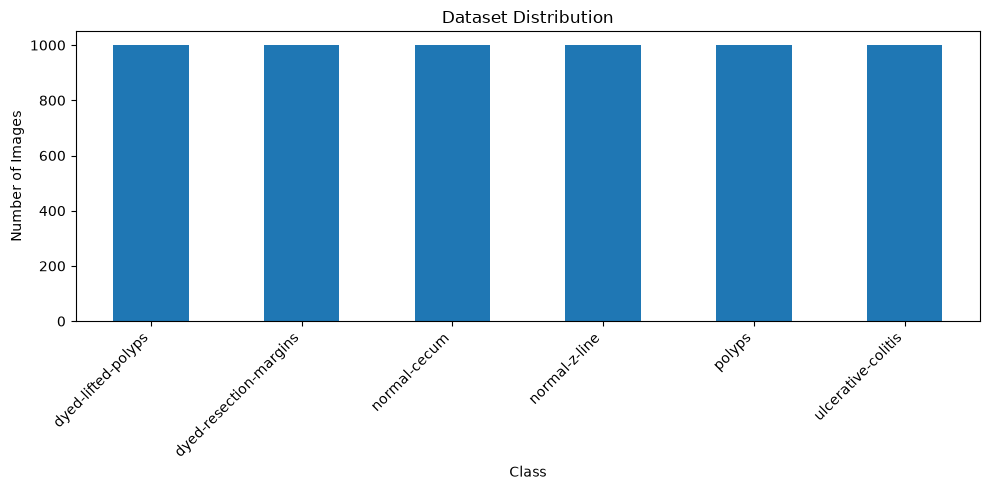

In [9]:
# ============================================================
# CELL 6 — DATASET DISTRIBUTION
# ============================================================

distribution = (
    df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

display(distribution)

plt.figure(figsize=(10, 5))

distribution.plot(
    kind="bar"
)

plt.title("Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# CELL 7 — TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=RANDOM_SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=RANDOM_SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4800
Validation: 600
Testing: 600


In [11]:
# ============================================================
# CELL 8 — VERIFY SPLIT
# ============================================================

print("TRAIN")
display(
    train_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

print("VALIDATION")
display(
    val_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

print("TEST")
display(
    test_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

TRAIN


class_name
dyed-lifted-polyps        800
dyed-resection-margins    800
normal-cecum              800
normal-z-line             800
polyps                    800
ulcerative-colitis        800
Name: count, dtype: int64

VALIDATION


class_name
dyed-lifted-polyps        100
dyed-resection-margins    100
normal-cecum              100
normal-z-line             100
polyps                    100
ulcerative-colitis        100
Name: count, dtype: int64

TEST


class_name
dyed-lifted-polyps        100
dyed-resection-margins    100
normal-cecum              100
normal-z-line             100
polyps                    100
ulcerative-colitis        100
Name: count, dtype: int64

In [12]:
# ============================================================
# CELL 9 — SAVE DATA SPLITS
# ============================================================

train_df.to_csv(
    DATA_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    DATA_DIR / "val.csv",
    index=False
)

test_df.to_csv(
    DATA_DIR / "test.csv",
    index=False
)

print("Dataset splits saved.")

Dataset splits saved.


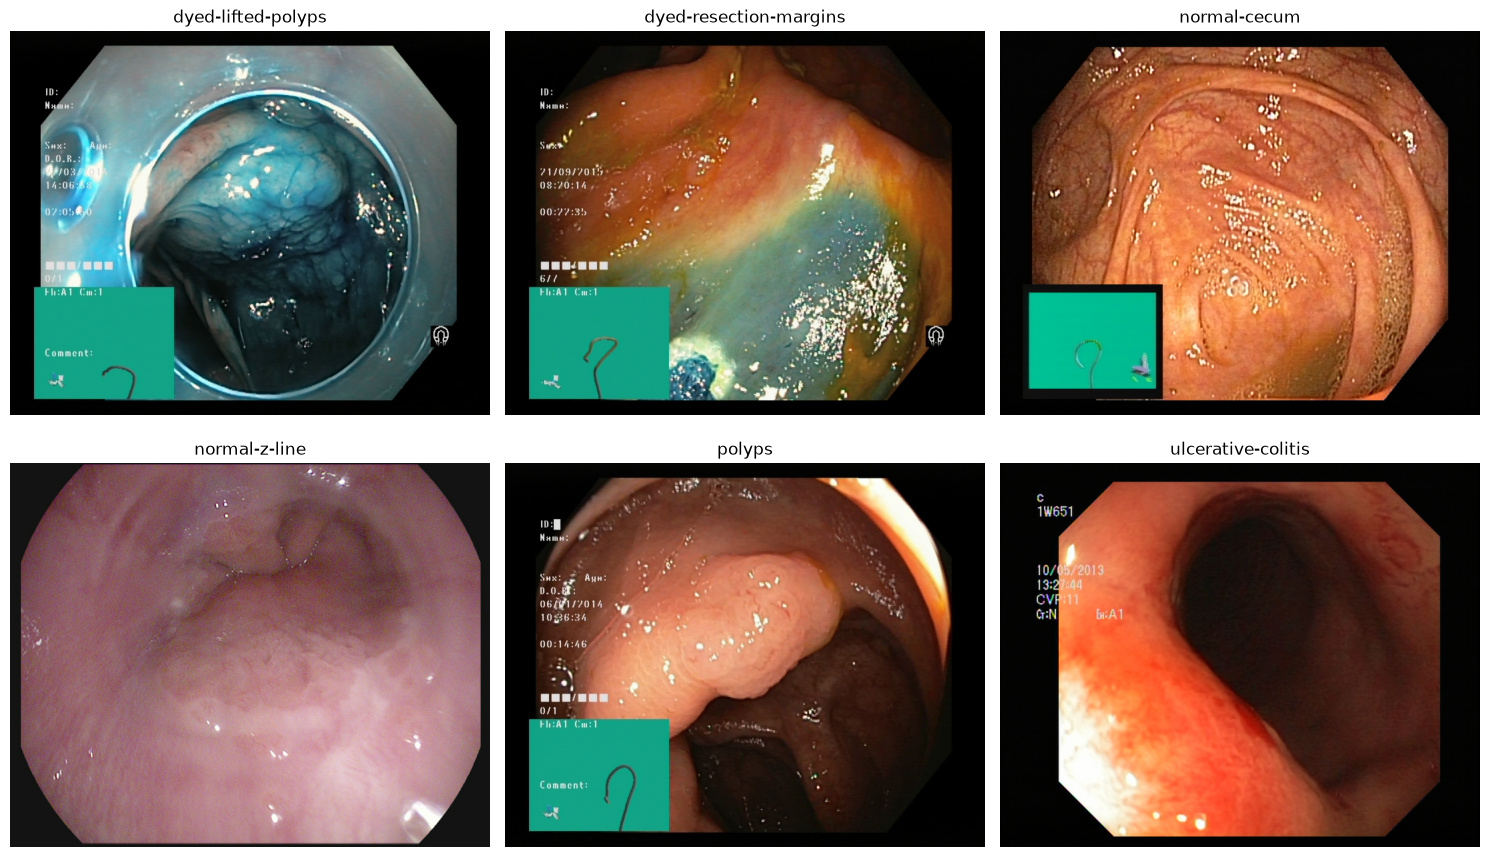

In [13]:
# ============================================================
# CELL 10 — VISUALIZE RANDOM DATASET SAMPLES
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, class_name in zip(axes.flat, CLASSES):

    class_images = df[
        df["class_name"] == class_name
    ]

    sample = class_images.sample(
        1,
        random_state=RANDOM_SEED
    ).iloc[0]

    image = Image.open(
        sample["image_path"]
    ).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CELL 11 — IMAGE SIZE CHECK
# ============================================================

sample_sizes = []

for image_path in df["image_path"].sample(
    min(100, len(df)),
    random_state=RANDOM_SEED
):

    with Image.open(image_path) as image:

        sample_sizes.append(
            image.size
        )

size_counts = pd.Series(
    sample_sizes
).value_counts()

display(size_counts.head(20))

(720, 576)      82
(1280, 1024)    12
(1920, 1072)     6
Name: count, dtype: int64

In [15]:
# ============================================================
# CELL 12 — IMAGE TRANSFORMATIONS
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Transforms created.")

Transforms created.


In [16]:
# ============================================================
# CELL 13 — PYTORCH DATASET
# ============================================================

class ColonDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = int(row["label"])

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(image)

        return image, label

In [17]:
# ============================================================
# CELL 14 — DATASET OBJECTS
# ============================================================

train_dataset = ColonDataset(
    train_df,
    transform=train_transform
)

val_dataset = ColonDataset(
    val_df,
    transform=eval_transform
)

test_dataset = ColonDataset(
    test_df,
    transform=eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 4800
Validation dataset: 600
Test dataset: 600


In [18]:
# ============================================================
# CELL 15 — DATALOADERS
# ============================================================

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 600
Validation batches: 75
Test batches: 75


In [19]:
# ============================================================
# CELL 16 — TEST DATA BATCH
# ============================================================

images, labels = next(
    iter(train_loader)
)

print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Labels:", labels)
print("Image dtype:", images.dtype)

Image tensor shape: torch.Size([8, 3, 224, 224])
Label tensor shape: torch.Size([8])
Labels: tensor([4, 5, 0, 4, 1, 0, 1, 5])
Image dtype: torch.float32


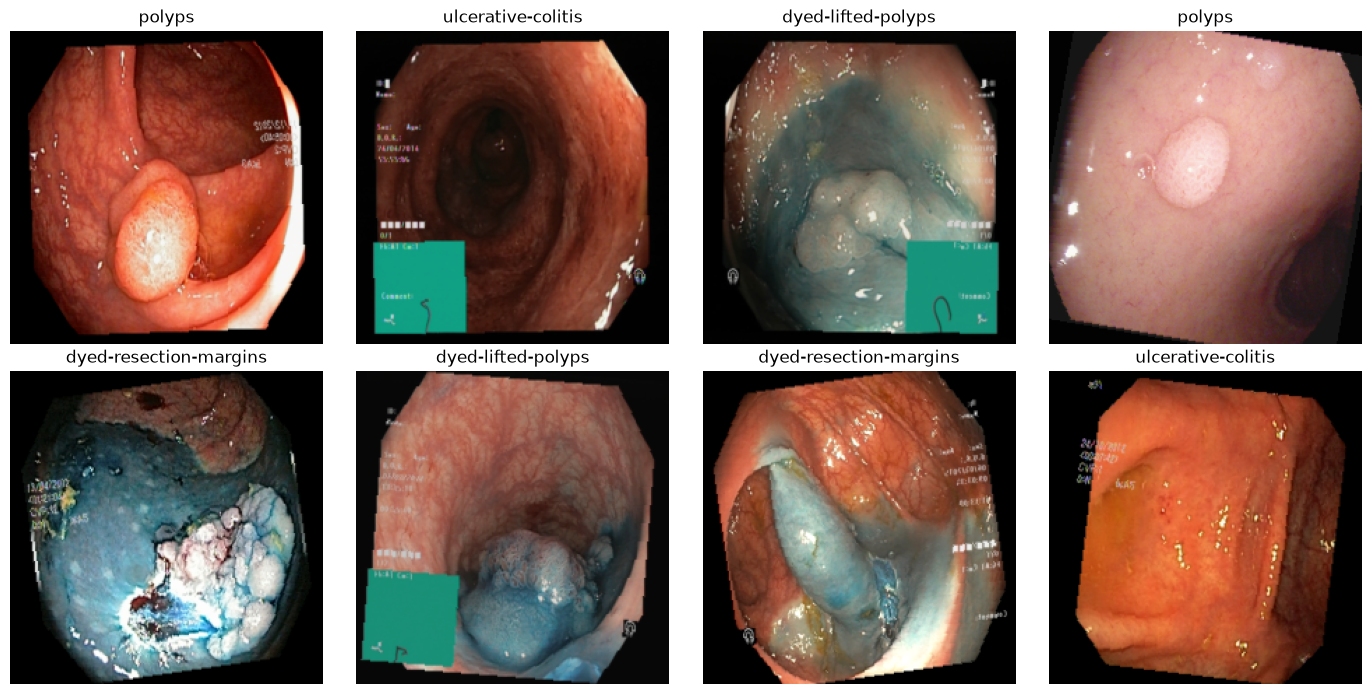

In [20]:
# ============================================================
# CELL 17 — VISUALIZE TRAINING BATCH
# ============================================================

def denormalize(image):

    mean = torch.tensor(
        IMAGENET_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD
    ).view(3, 1, 1)

    image = image.cpu() * std + mean

    return torch.clamp(
        image,
        0,
        1
    )


fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

for i, ax in enumerate(axes.flat):

    image = denormalize(
        images[i]
    )

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        INDEX_TO_CLASS[
            labels[i].item()
        ]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# CELL 18 — LOAD PRETRAINED VIT
# ============================================================

MODEL_NAME = "vit_tiny_patch16_224"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

print(model)

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): Attention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=192, out_features=192, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=192, out_features=768, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(

In [22]:
# ============================================================
# CELL 19 — MODEL FORWARD PASS
# ============================================================

model.eval()

with torch.no_grad():

    sample_images = images.to(
        DEVICE
    )

    outputs = model(
        sample_images
    )

print(
    "Input shape:",
    sample_images.shape
)

print(
    "Output shape:",
    outputs.shape
)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 6])


In [23]:
# ============================================================
# CELL 20 — LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Loss: CrossEntropyLoss()
Optimizer: AdamW


In [24]:
# ============================================================
# CELL 21 — TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device
        )

        labels = labels.to(
            device
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy

In [25]:
# ============================================================
# CELL 22 — VALIDATION FUNCTION
# ============================================================

def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device
            )

            labels = labels.to(
                device
            )

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [26]:
# ============================================================
# CELL 23 — VIT TRAINING
# ============================================================

NUM_EPOCHS = 15

best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}


best_model_path = (
    MODEL_DIR / "best_vit_tiny.pth"
)


for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    (
        val_loss,
        val_accuracy,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_accuracy * 100:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            "✓ Best model saved."
        )


print(
    "\nTraining complete."
)

print(
    f"Best validation accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)


Epoch 1/15
Train Loss: 0.3959
Train Accuracy: 84.71%
Val Loss: 0.3303
Val Accuracy: 88.83%
✓ Best model saved.

Epoch 2/15
Train Loss: 0.1950
Train Accuracy: 93.02%
Val Loss: 0.1463
Val Accuracy: 95.00%
✓ Best model saved.

Epoch 3/15
Train Loss: 0.1723
Train Accuracy: 94.06%
Val Loss: 0.2019
Val Accuracy: 92.83%

Epoch 4/15
Train Loss: 0.1355
Train Accuracy: 94.92%
Val Loss: 0.1602
Val Accuracy: 94.50%

Epoch 5/15
Train Loss: 0.1136
Train Accuracy: 95.88%
Val Loss: 0.2290
Val Accuracy: 91.67%

Epoch 6/15
Train Loss: 0.1090
Train Accuracy: 96.04%
Val Loss: 0.1922
Val Accuracy: 93.83%

Epoch 7/15
Train Loss: 0.1008
Train Accuracy: 96.31%
Val Loss: 0.2146
Val Accuracy: 92.67%

Epoch 8/15
Train Loss: 0.0956
Train Accuracy: 96.71%
Val Loss: 0.2505
Val Accuracy: 90.83%

Epoch 9/15
Train Loss: 0.0980
Train Accuracy: 96.31%
Val Loss: 0.1873
Val Accuracy: 93.67%

Epoch 10/15
Train Loss: 0.0634
Train Accuracy: 97.85%
Val Loss: 0.1955
Val Accuracy: 93.67%

Epoch 11/15
Train Loss: 0.0803
Train A

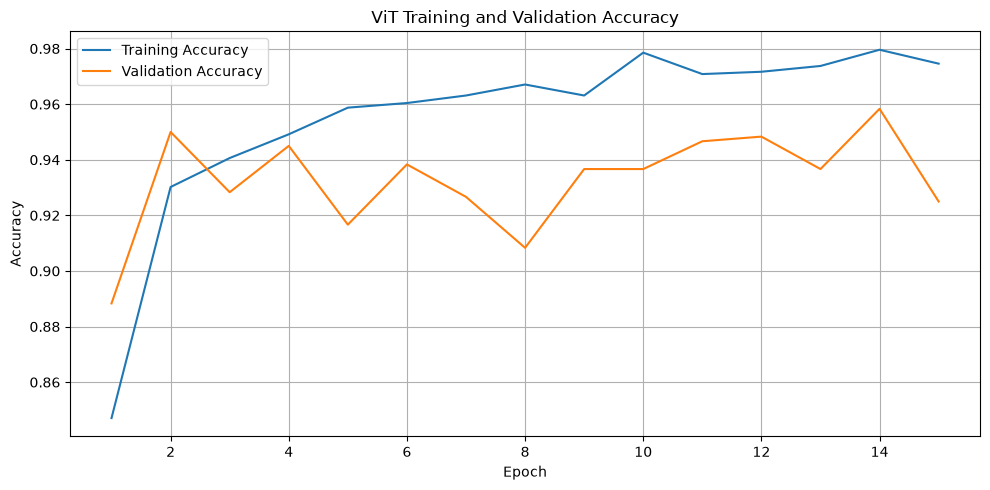

In [27]:
# ============================================================
# CELL 24 — TRAINING CURVES
# ============================================================

epochs = range(
    1,
    NUM_EPOCHS + 1
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ViT Training and Validation Accuracy"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "vit_accuracy.png",
    dpi=300
)

plt.show()

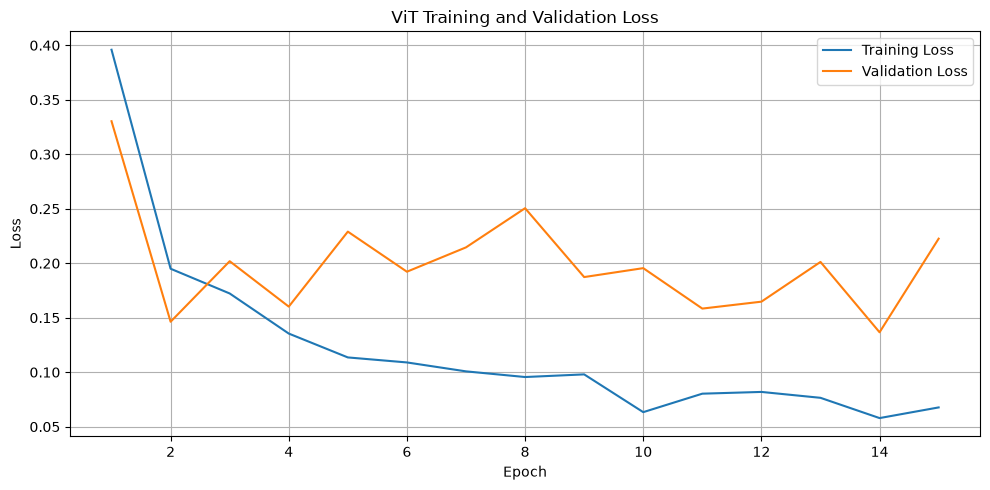

In [28]:
# ============================================================
# CELL 25 — LOSS CURVES
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ViT Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "vit_loss.png",
    dpi=300
)

plt.show()

In [29]:
# ============================================================
# CELL 26 — LOAD BEST VIT MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Best ViT model loaded.")

Best ViT model loaded.


In [30]:
# ============================================================
# CELL 27 — TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy, test_labels, test_predictions = evaluate(
    model,
    test_loader,
    criterion,
    DEVICE
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.1671
Test Accuracy: 95.50%


In [31]:
# ============================================================
# CELL 28 — CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASSES,
    digits=4
)

print(report)


                        precision    recall  f1-score   support

    dyed-lifted-polyps     0.9048    0.9500    0.9268       100
dyed-resection-margins     0.9677    0.9000    0.9326       100
          normal-cecum     0.9700    0.9700    0.9700       100
         normal-z-line     1.0000    1.0000    1.0000       100
                polyps     0.9151    0.9700    0.9417       100
    ulcerative-colitis     0.9792    0.9400    0.9592       100

              accuracy                         0.9550       600
             macro avg     0.9561    0.9550    0.9551       600
          weighted avg     0.9561    0.9550    0.9551       600



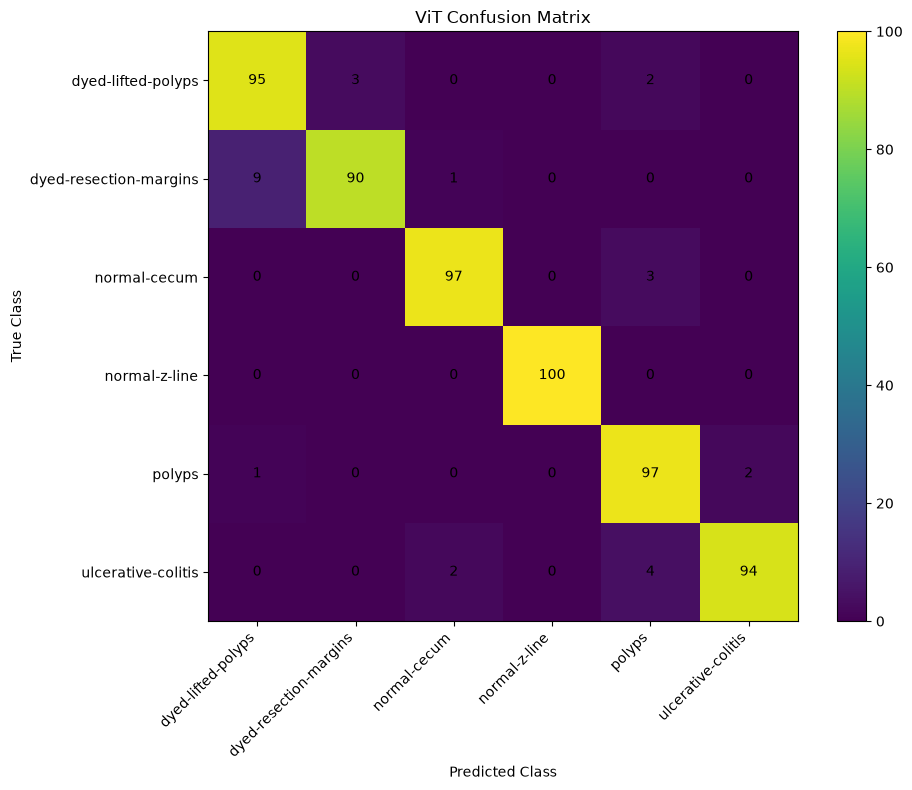

In [32]:
# ============================================================
# CELL 29 — CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASSES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "ViT Confusion Matrix"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "vit_confusion_matrix.png",
    dpi=300
)

plt.show()

In [33]:
# ============================================================
# CELL 30 — EXTRACT VIT FEATURE EMBEDDINGS
# ============================================================

# Load the best trained model
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Best ViT model loaded.")

Best ViT model loaded.


In [34]:
# ============================================================
# CELL 31 — VIT FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_features(model, loader, device):

    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract ViT features before classification head
            features = model.forward_features(images)

            # ViT output:
            # [batch, tokens, embedding_dimension]

            # Use CLS token
            cls_features = features[:, 0, :]

            all_features.append(
                cls_features.cpu()
            )

            all_labels.append(
                labels
            )

    all_features = torch.cat(
        all_features,
        dim=0
    )

    all_labels = torch.cat(
        all_labels,
        dim=0
    )

    return all_features, all_labels

In [35]:
# ============================================================
# CELL 32 — EXTRACT ALL EMBEDDINGS
# ============================================================

train_features, train_labels = extract_features(
    model,
    train_loader,
    DEVICE
)

val_features, val_labels = extract_features(
    model,
    val_loader,
    DEVICE
)

test_features, test_labels = extract_features(
    model,
    test_loader,
    DEVICE
)

print(
    "Train features:",
    train_features.shape
)

print(
    "Validation features:",
    val_features.shape
)

print(
    "Test features:",
    test_features.shape
)

Train features: torch.Size([4800, 192])
Validation features: torch.Size([600, 192])
Test features: torch.Size([600, 192])


In [36]:
# ============================================================
# CELL 33 — SAVE EMBEDDINGS
# ============================================================

torch.save(
    {
        "features": train_features,
        "labels": train_labels
    },
    EMBEDDING_DIR / "train_embeddings.pt"
)

torch.save(
    {
        "features": val_features,
        "labels": val_labels
    },
    EMBEDDING_DIR / "val_embeddings.pt"
)

torch.save(
    {
        "features": test_features,
        "labels": test_labels
    },
    EMBEDDING_DIR / "test_embeddings.pt"
)

print("Embeddings saved successfully.")

Embeddings saved successfully.


In [39]:
# ============================================================
# CELL 34 — PYTORCH GEOMETRIC CHECK
# ============================================================

try:
    import torch_geometric

    print("PyTorch Geometric version:",
          torch_geometric.__version__)

except ImportError:
    print("PyTorch Geometric is not installed.")
    print("Install it with:")
    print("pip install torch-geometric")

PyTorch Geometric version: 2.8.0.post1


/Users/sudeep/Documents/Major Project/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [40]:
# ============================================================
# CELL 35 — GRAPH IMPORTS
# ============================================================

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

from torch_geometric.data import Data
from torch_geometric.nn import (
    GCNConv,
    GATConv,
    SAGEConv,
    GINConv
)

print("Graph libraries imported successfully.")

Graph libraries imported successfully.


In [41]:
# ============================================================
# CELL 36 — PREPARE TRAINING FEATURES
# ============================================================

X_train = train_features.numpy()
y_train = train_labels.numpy()

print("Feature matrix:", X_train.shape)
print("Label vector:", y_train.shape)

Feature matrix: (4800, 192)
Label vector: (4800,)


In [42]:
# ============================================================
# CELL 37 — NORMALIZE FEATURES
# ============================================================

X_train_normalized = normalize(
    X_train,
    norm="l2"
)

print(
    "Normalized feature shape:",
    X_train_normalized.shape
)



Normalized feature shape: (4800, 192)


In [43]:
# ============================================================
# CELL 38 — BUILD K-NN GRAPH
# ============================================================

K = 5

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine"
)

knn.fit(X_train_normalized)

distances, neighbors = knn.kneighbors(
    X_train_normalized
)

print("Distances shape:", distances.shape)
print("Neighbors shape:", neighbors.shape)

Distances shape: (4800, 6)
Neighbors shape: (4800, 6)


In [44]:
# ============================================================
# CELL 39 — CREATE GRAPH EDGES
# ============================================================

edge_list = []

for node in range(len(X_train_normalized)):

    for j in range(1, K + 1):

        neighbor = neighbors[node, j]

        edge_list.append(
            [node, neighbor]
        )

edge_index = torch.tensor(
    edge_list,
    dtype=torch.long
).t().contiguous()

print("Edge index shape:", edge_index.shape)
print("Number of directed edges:", edge_index.shape[1])

Edge index shape: torch.Size([2, 24000])
Number of directed edges: 24000


In [45]:
# ============================================================
# CELL 40 — MAKE GRAPH UNDIRECTED
# ============================================================

from torch_geometric.utils import to_undirected

edge_index = to_undirected(
    edge_index
)

print(
    "Undirected edge index shape:",
    edge_index.shape
)

Undirected edge index shape: torch.Size([2, 40216])


In [46]:
# ============================================================
# CELL 41 — CREATE TRAINING GRAPH
# ============================================================

graph_data = Data(
    x=train_features.float(),
    edge_index=edge_index,
    y=train_labels.long()
)

print(graph_data)

Data(x=[4800, 192], edge_index=[2, 40216], y=[4800])


In [47]:
# ============================================================
# CELL 42 — BUILD VALIDATION GRAPH
# ============================================================

X_val = val_features.numpy()

X_val_normalized = normalize(
    X_val,
    norm="l2"
)

K = 5

val_knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine"
)

val_knn.fit(X_val_normalized)

val_distances, val_neighbors = val_knn.kneighbors(
    X_val_normalized
)

print("Validation distances:", val_distances.shape)
print("Validation neighbors:", val_neighbors.shape)

Validation distances: (600, 6)
Validation neighbors: (600, 6)


In [48]:
# ============================================================
# CELL 43 — VALIDATION GRAPH EDGES
# ============================================================

val_edge_list = []

for node in range(len(X_val_normalized)):

    for j in range(1, K + 1):

        neighbor = val_neighbors[node, j]

        val_edge_list.append(
            [node, neighbor]
        )

val_edge_index = torch.tensor(
    val_edge_list,
    dtype=torch.long
).t().contiguous()

print(
    "Initial validation edges:",
    val_edge_index.shape
)

Initial validation edges: torch.Size([2, 3000])


In [49]:
# ============================================================
# CELL 44 — UNDIRECTED VALIDATION GRAPH
# ============================================================

val_edge_index = to_undirected(
    val_edge_index
)

print(
    "Final validation edges:",
    val_edge_index.shape
)

Final validation edges: torch.Size([2, 4682])


In [50]:
# ============================================================
# CELL 45 — VALIDATION GRAPH DATA
# ============================================================

val_graph = Data(
    x=val_features.float(),
    edge_index=val_edge_index,
    y=val_labels.long()
)

print(val_graph)

Data(x=[600, 192], edge_index=[2, 4682], y=[600])


In [51]:
# ============================================================
# CELL 46 — BUILD TEST GRAPH
# ============================================================

X_test = test_features.numpy()

X_test_normalized = normalize(
    X_test,
    norm="l2"
)

test_knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine"
)

test_knn.fit(X_test_normalized)

test_distances, test_neighbors = test_knn.kneighbors(
    X_test_normalized
)

print("Test distances:", test_distances.shape)
print("Test neighbors:", test_neighbors.shape)

Test distances: (600, 6)
Test neighbors: (600, 6)


In [52]:
# ============================================================
# CELL 47 — TEST GRAPH EDGES
# ============================================================

test_edge_list = []

for node in range(len(X_test_normalized)):

    for j in range(1, K + 1):

        neighbor = test_neighbors[node, j]

        test_edge_list.append(
            [node, neighbor]
        )

test_edge_index = torch.tensor(
    test_edge_list,
    dtype=torch.long
).t().contiguous()

print(
    "Initial test edges:",
    test_edge_index.shape
)

Initial test edges: torch.Size([2, 3000])


In [53]:
# ============================================================
# CELL 48 — UNDIRECTED TEST GRAPH
# ============================================================

test_edge_index = to_undirected(
    test_edge_index
)

print(
    "Final test edges:",
    test_edge_index.shape
)

Final test edges: torch.Size([2, 4762])


In [54]:
# ============================================================
# CELL 49 — TEST GRAPH DATA
# ============================================================

test_graph = Data(
    x=test_features.float(),
    edge_index=test_edge_index,
    y=test_labels.long()
)

print(test_graph)

Data(x=[600, 192], edge_index=[2, 4762], y=[600])


In [55]:
# ============================================================
# CELL 50 — MOVE GRAPHS TO DEVICE
# ============================================================

graph_data = graph_data.to(DEVICE)
val_graph = val_graph.to(DEVICE)
test_graph = test_graph.to(DEVICE)

print("Training graph:", graph_data.x.device)
print("Validation graph:", val_graph.x.device)
print("Test graph:", test_graph.x.device)

Training graph: mps:0
Validation graph: mps:0
Test graph: mps:0


In [56]:
# ============================================================
# CELL 51 — GCN MODEL
# ============================================================

class GCN(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        num_classes,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        self.conv3 = GCNConv(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout

    def forward(
        self,
        x,
        edge_index
    ):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv3(
            x,
            edge_index
        )

        return x

In [58]:
# ============================================================
# CELL 52 — INITIALIZE GCN
# ============================================================

gcn_model = GCN(
    input_dim=192,
    hidden_dim=128,
    num_classes=NUM_CLASSES,
    dropout=0.3
).to(DEVICE)

print(gcn_model)

GCN(
  (conv1): GCNConv(192, 128)
  (conv2): GCNConv(128, 128)
  (conv3): GCNConv(128, 6)
)


In [59]:
# ============================================================
# CELL 53 — LOSS AND OPTIMIZER
# ============================================================

gcn_criterion = nn.CrossEntropyLoss()

gcn_optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

print("GCN optimizer ready.")

GCN optimizer ready.


In [61]:
# ============================================================
# CELL 54 — TRAIN GCN
# ============================================================
# ============================================================
# IMPORT PYTORCH FUNCTIONAL API
# ============================================================

import torch.nn.functional as F

print("F imported successfully.")
GCN_EPOCHS = 100

gcn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_gcn_val_accuracy = 0.0

best_gcn_path = (
    MODEL_DIR / "best_gcn.pth"
)


for epoch in range(1, GCN_EPOCHS + 1):

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    gcn_model.train()

    gcn_optimizer.zero_grad()

    train_output = gcn_model(
        graph_data.x,
        graph_data.edge_index
    )

    train_loss = gcn_criterion(
        train_output,
        graph_data.y
    )

    train_loss.backward()

    gcn_optimizer.step()


    # --------------------------------------------------------
    # TRAIN ACCURACY
    # --------------------------------------------------------

    gcn_model.eval()

    with torch.no_grad():

        train_predictions = (
            train_output.argmax(dim=1)
        )

        train_accuracy = (
            train_predictions
            == graph_data.y
        ).float().mean().item()


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_output = gcn_model(
            val_graph.x,
            val_graph.edge_index
        )

        val_predictions = (
            val_output.argmax(dim=1)
        )

        val_accuracy = (
            val_predictions
            == val_graph.y
        ).float().mean().item()


    # --------------------------------------------------------
    # STORE HISTORY
    # --------------------------------------------------------

    gcn_history["train_loss"].append(
        train_loss.item()
    )

    gcn_history["train_accuracy"].append(
        train_accuracy
    )

    gcn_history["val_accuracy"].append(
        val_accuracy
    )


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_accuracy > best_gcn_val_accuracy:

        best_gcn_val_accuracy = val_accuracy

        torch.save(
            gcn_model.state_dict(),
            best_gcn_path
        )


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {train_loss.item():.4f} | "
            f"Train Acc: {train_accuracy*100:.2f}% | "
            f"Val Acc: {val_accuracy*100:.2f}%"
        )


print("\nGCN training complete.")

print(
    f"Best validation accuracy: "
    f"{best_gcn_val_accuracy*100:.2f}%"
)

F imported successfully.
Epoch 001 | Loss: 4.8183 | Train Acc: 3.17% | Val Acc: 33.17%
Epoch 010 | Loss: 0.0385 | Train Acc: 98.92% | Val Acc: 95.67%
Epoch 020 | Loss: 0.0358 | Train Acc: 98.98% | Val Acc: 95.50%
Epoch 030 | Loss: 0.0341 | Train Acc: 99.08% | Val Acc: 95.67%
Epoch 040 | Loss: 0.0354 | Train Acc: 99.02% | Val Acc: 95.67%
Epoch 050 | Loss: 0.0350 | Train Acc: 98.92% | Val Acc: 95.67%
Epoch 060 | Loss: 0.0306 | Train Acc: 99.02% | Val Acc: 95.67%
Epoch 070 | Loss: 0.0272 | Train Acc: 99.12% | Val Acc: 95.67%
Epoch 080 | Loss: 0.0289 | Train Acc: 99.02% | Val Acc: 95.67%
Epoch 090 | Loss: 0.0282 | Train Acc: 99.02% | Val Acc: 95.67%
Epoch 100 | Loss: 0.0277 | Train Acc: 99.10% | Val Acc: 95.67%

GCN training complete.
Best validation accuracy: 95.83%


In [62]:
# ============================================================
# CELL 55 — LOAD BEST GCN
# ============================================================

gcn_model.load_state_dict(
    torch.load(
        best_gcn_path,
        map_location=DEVICE
    )
)

gcn_model = gcn_model.to(DEVICE)
gcn_model.eval()

print("Best GCN model loaded.")

Best GCN model loaded.


In [63]:
# ============================================================
# CELL 56 — GCN TEST EVALUATION
# ============================================================

with torch.no_grad():

    test_output = gcn_model(
        test_graph.x,
        test_graph.edge_index
    )

    gcn_test_predictions = (
        test_output.argmax(dim=1)
    )

gcn_test_accuracy = (
    gcn_test_predictions
    == test_graph.y
).float().mean().item()

print(
    f"GCN Test Accuracy: "
    f"{gcn_test_accuracy * 100:.2f}%"
)

GCN Test Accuracy: 94.50%


In [64]:
# ============================================================
# CELL 57 — GCN CLASSIFICATION REPORT
# ============================================================

gcn_test_labels_np = (
    test_graph.y
    .cpu()
    .numpy()
)

gcn_predictions_np = (
    gcn_test_predictions
    .cpu()
    .numpy()
)

print(
    classification_report(
        gcn_test_labels_np,
        gcn_predictions_np,
        target_names=CLASSES,
        digits=4
    )
)

                        precision    recall  f1-score   support

    dyed-lifted-polyps     0.9100    0.9100    0.9100       100
dyed-resection-margins     0.9192    0.9100    0.9146       100
          normal-cecum     0.9423    0.9800    0.9608       100
         normal-z-line     1.0000    1.0000    1.0000       100
                polyps     0.9400    0.9400    0.9400       100
    ulcerative-colitis     0.9588    0.9300    0.9442       100

              accuracy                         0.9450       600
             macro avg     0.9450    0.9450    0.9449       600
          weighted avg     0.9450    0.9450    0.9449       600



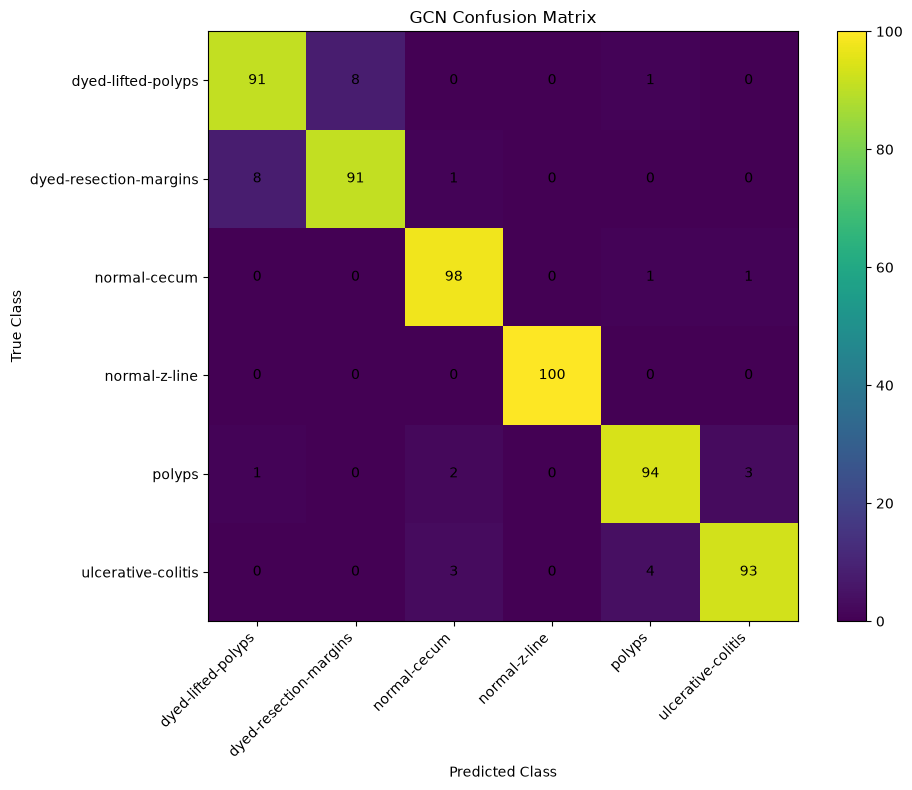

In [65]:
# ============================================================
# CELL 58 — GCN CONFUSION MATRIX
# ============================================================

gcn_cm = confusion_matrix(
    gcn_test_labels_np,
    gcn_predictions_np
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(gcn_cm)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASSES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "GCN Confusion Matrix"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            gcn_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_confusion_matrix.png",
    dpi=300
)

plt.show()

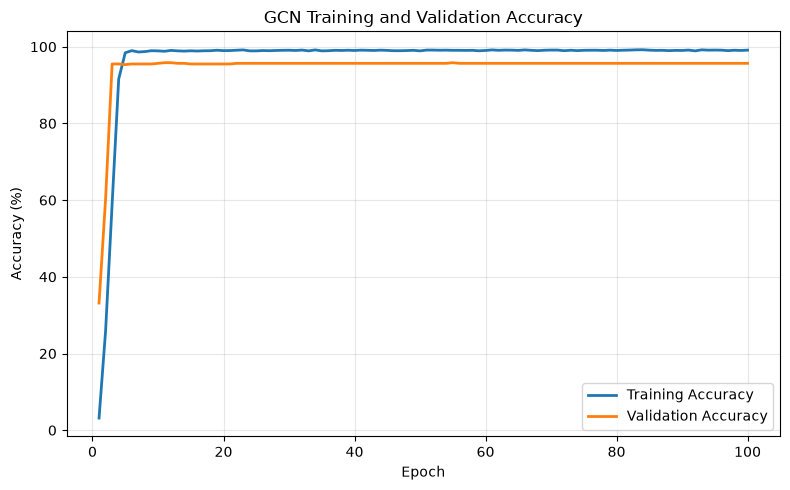

In [66]:
# ============================================================
# GCN TRAINING vs VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(gcn_history["train_accuracy"]) + 1),
    [x * 100 for x in gcn_history["train_accuracy"]],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    range(1, len(gcn_history["val_accuracy"]) + 1),
    [x * 100 for x in gcn_history["val_accuracy"]],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("GCN Training and Validation Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

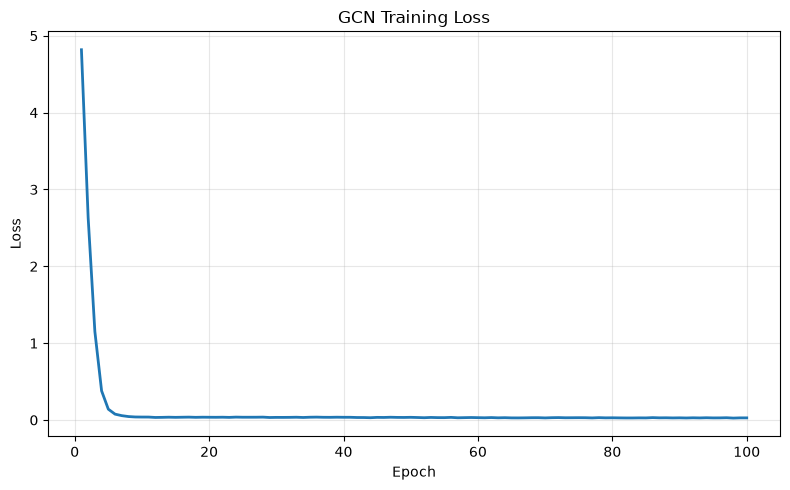

In [67]:
# ============================================================
# GCN TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(gcn_history["train_loss"]) + 1),
    gcn_history["train_loss"],
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GCN Training Loss")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

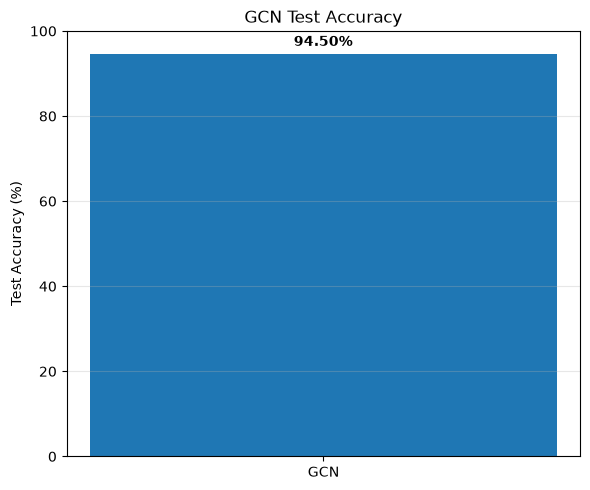

In [68]:
# ============================================================
# GCN TEST ACCURACY
# ============================================================

plt.figure(figsize=(6, 5))

bars = plt.bar(
    ["GCN"],
    [gcn_test_accuracy * 100]
)

plt.ylabel("Test Accuracy (%)")
plt.title("GCN Test Accuracy")

plt.ylim(0, 100)

plt.text(
    0,
    gcn_test_accuracy * 100 + 2,
    f"{gcn_test_accuracy * 100:.2f}%",
    ha="center",
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

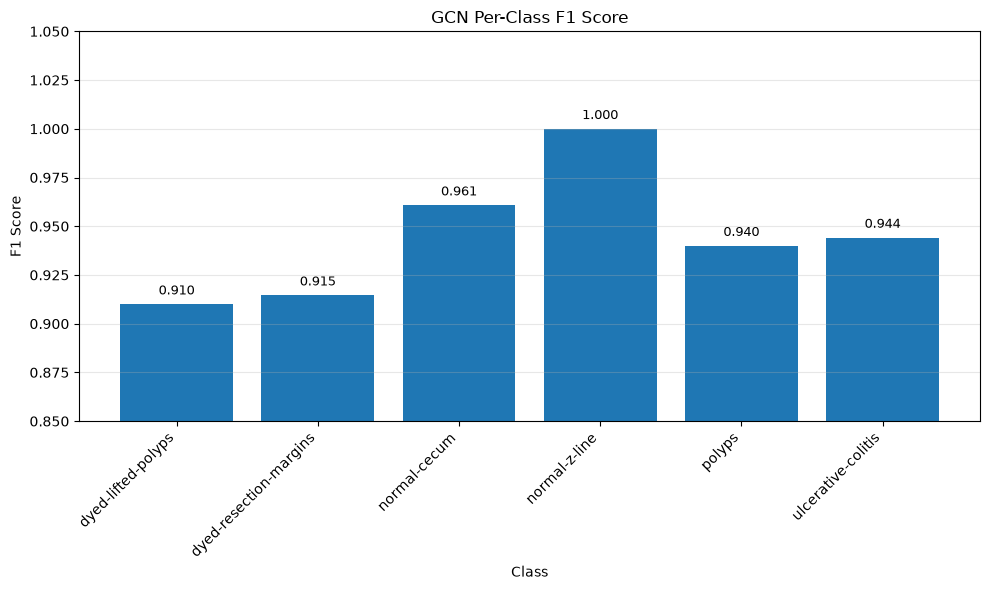

In [69]:
# ============================================================
# GCN PER-CLASS F1 SCORE
# ============================================================

gcn_f1_scores = [
    0.9100,
    0.9146,
    0.9608,
    1.0000,
    0.9400,
    0.9442
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    CLASSES,
    gcn_f1_scores
)

plt.xlabel("Class")
plt.ylabel("F1 Score")
plt.title("GCN Per-Class F1 Score")

plt.ylim(0.85, 1.05)

plt.xticks(
    rotation=45,
    ha="right"
)

for bar, score in zip(
    bars,
    gcn_f1_scores
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{score:.3f}",
        ha="center",
        fontsize=9
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_per_class_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()